# 02 — TF-IDF + logistic regression

Model 1 is a scikit-learn pipeline: TF-IDF on the claim and the evidence, plus a flag for missing evidence, then class-balanced logistic regression.
The same `C` grid is used for every input mode. This notebook only reads the saved metrics, predictions, and the top-feature figure.


In [1]:
from pathlib import Path
import sys

import pandas as pd
from IPython.display import Image, display

ROOT = Path.cwd().resolve()
if not (ROOT / "src").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from src import config as C
from src.evaluate import load_metrics, load_predictions

rows = []
majority = load_metrics("majority", "full")
rows.append({
    "model": "majority",
    "input_mode": "full",
    "accuracy": majority["accuracy"],
    "macro_f1": majority["macro_f1"],
    "best_params": majority["best_params"],
    "cv_macro_f1": majority["cv_macro_f1"],
})
for mode in C.INPUT_MODES:
    metrics = load_metrics("tfidf_lr", mode)
    rows.append({
        "model": "tfidf_lr",
        "input_mode": mode,
        "accuracy": metrics["accuracy"],
        "macro_f1": metrics["macro_f1"],
        "best_params": metrics["best_params"],
        "cv_macro_f1": metrics["cv_macro_f1"],
    })
pd.DataFrame(rows)


,model,input_mode,accuracy,macro_f1,best_params,cv_macro_f1
0,majority,full,0.626283,0.192551,{'strategy': 'most_frequent'},NaN
1,tfidf_lr,full,0.646817,0.469327,"{'ngram_range': [1, 2], 'C': 1.0}",0.540376
2,tfidf_lr,claim_only,0.537988,0.331703,"{'ngram_range': [1, 2], 'C': 1.0}",0.399286
3,tfidf_lr,evidence_only,0.624230,0.446232,"{'ngram_range': [1, 2], 'C': 1.0}",0.559384


## Top positive coefficients

Teal bars are claim features and orange bars are evidence features. These are associations in the training set, not proof of what makes a claim true.


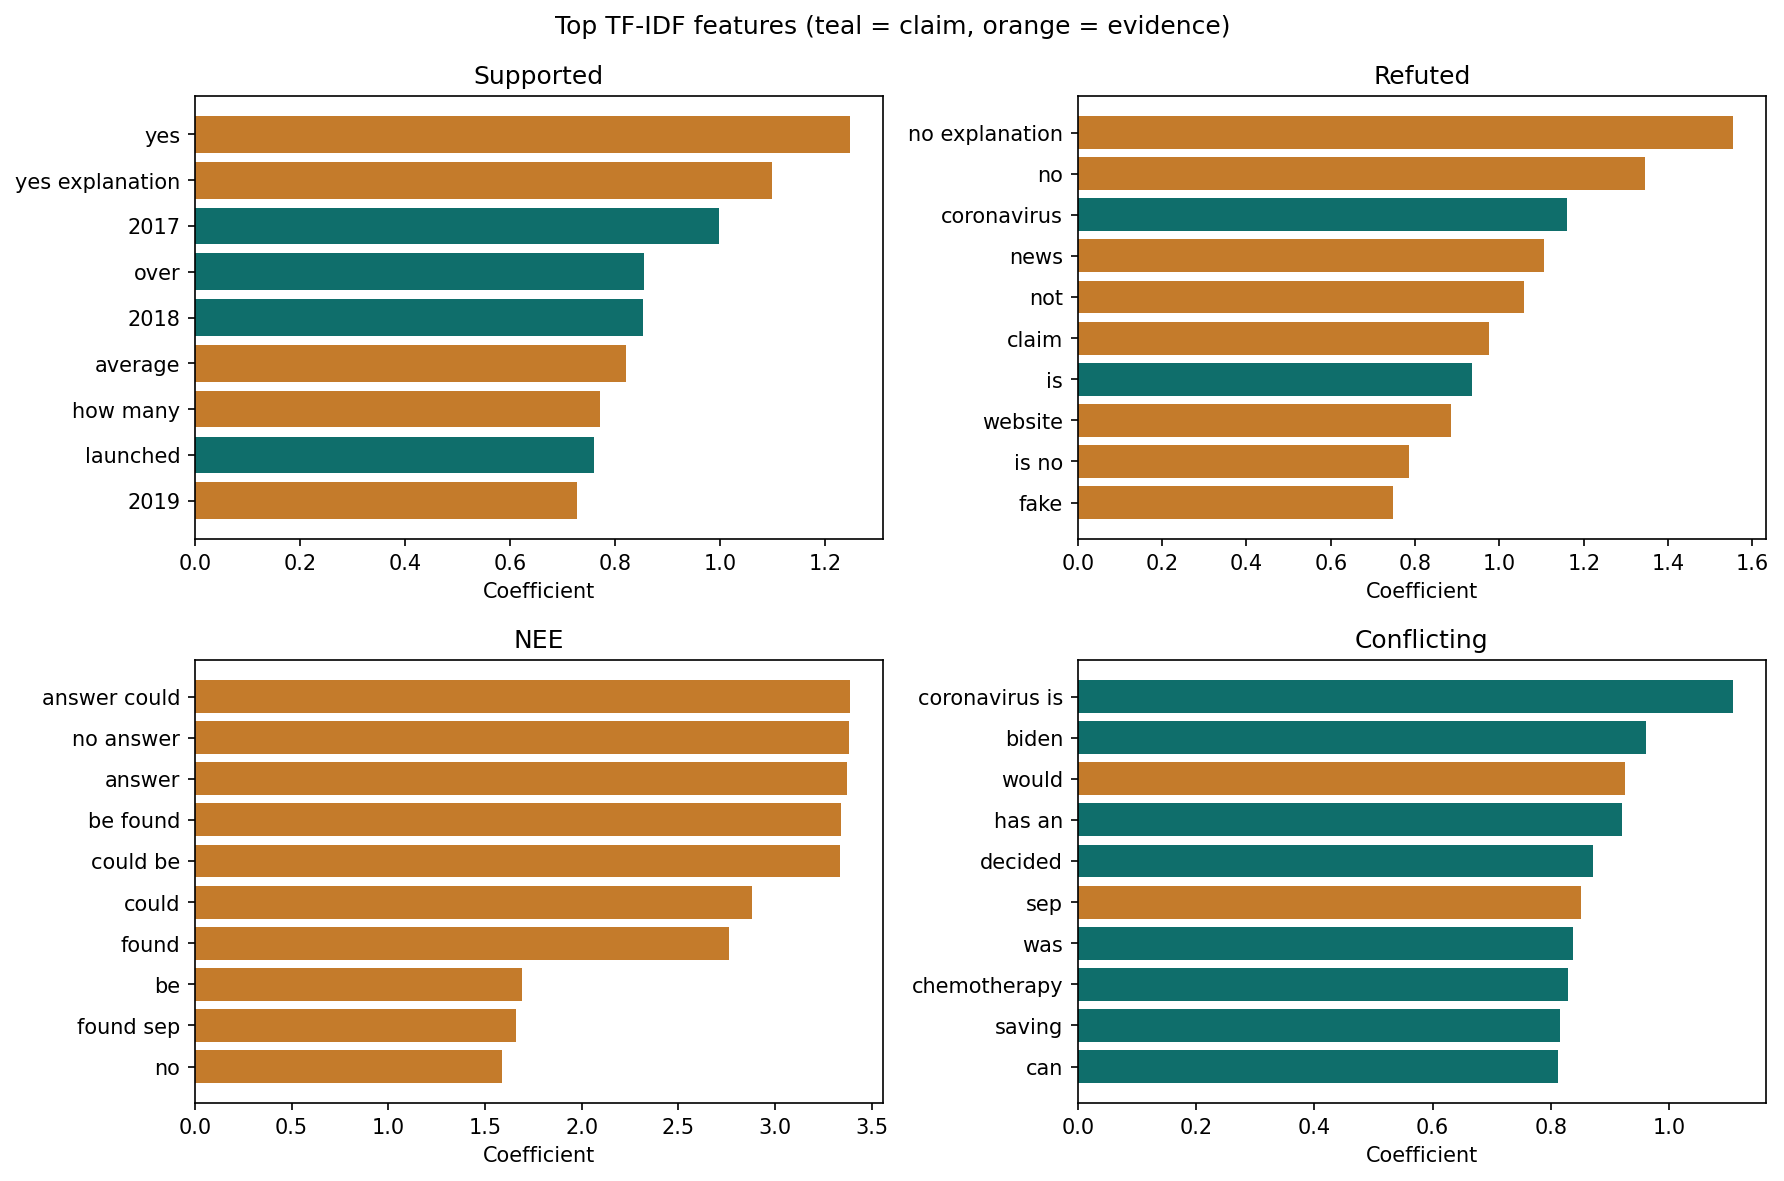

In [2]:
display(Image(filename=str(C.FIGURES_DIR / "tfidf_top_words.png")))


## A few test predictions

The first rows, then a few mistakes. `correct` is 1 when the predicted verdict matches the dev label.


In [3]:
predictions = load_predictions("tfidf_lr", "full")
predictions.head(8)


,claim_id,y_true,y_pred,correct,proba_Supported,proba_Refuted,proba_Not Enough Evidence,proba_Conflicting Evidence/Cherrypicking
0,0,Refuted,Refuted,1,0.159365,0.664385,0.066776,0.109475
1,1,Refuted,Refuted,1,0.262456,0.576685,0.092882,0.067976
2,2,Refuted,Not Enough Evidence,0,0.083274,0.409997,0.433230,0.073499
3,3,Refuted,Not Enough Evidence,0,0.142968,0.260867,0.458906,0.137259
4,4,Refuted,Not Enough Evidence,0,0.102276,0.283122,0.387031,0.227571
5,5,Refuted,Refuted,1,0.325565,0.435043,0.123248,0.116145
6,6,Supported,Refuted,0,0.285393,0.449893,0.142584,0.122130
7,7,Supported,Supported,1,0.361046,0.355787,0.103415,0.179753


In [4]:
predictions.loc[predictions["correct"] == 0].head(5)


,claim_id,y_true,y_pred,correct,proba_Supported,proba_Refuted,proba_Not Enough Evidence,proba_Conflicting Evidence/Cherrypicking
2,2,Refuted,Not Enough Evidence,0,0.083274,0.409997,0.433230,0.073499
3,3,Refuted,Not Enough Evidence,0,0.142968,0.260867,0.458906,0.137259
4,4,Refuted,Not Enough Evidence,0,0.102276,0.283122,0.387031,0.227571
6,6,Supported,Refuted,0,0.285393,0.449893,0.142584,0.122130
10,10,Conflicting Evidence/Cherrypicking,Refuted,0,0.252072,0.498355,0.160778,0.088794
